<a href="https://colab.research.google.com/github/RizkiHadiono/244107020198-Pembelajaran-Mesin/blob/main/JS11_244107020198_MOKHAMAD_RIZKI_HADIONO_SINGGIH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jobsheet Klasifikasi SVM
**Praktikum 1 sampai Praktikum 5 dan Tugas Praktikum**

# Praktikum 1 — SVM dengan Data Dummy Linier

## Langkah 1 — Import Library
Mengimpor pustaka yang diperlukan untuk membuat data, melatih SVM, dan menampilkan grafik.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

## Langkah 2 — Membuat Data Dummy
Membuat 50 titik data dalam dua kelas yang relatif mudah dipisahkan.

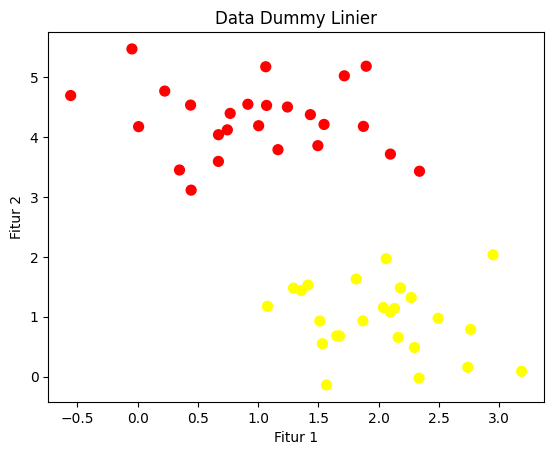

In [2]:
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title('Data Dummy Linier')
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.show()

## Langkah 3 — Ilustrasi Garis Pemisah
Beberapa garis dapat memisahkan dua kelas, tetapi belum tentu semuanya menghasilkan margin terbaik.

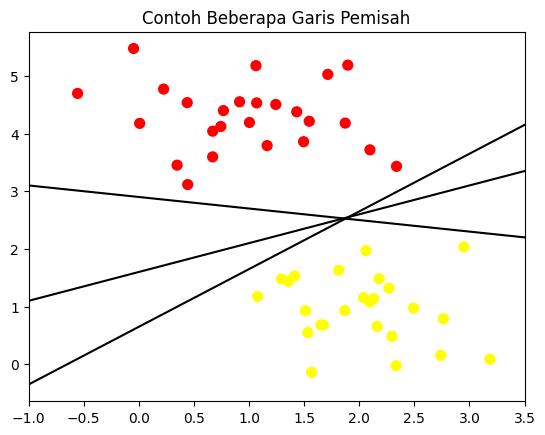

In [3]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5)
plt.title('Contoh Beberapa Garis Pemisah')
plt.show()

## Langkah 4 — Ilustrasi Margin
Area abu-abu menunjukkan margin di sekitar garis. SVM berusaha mencari batas pemisah dengan margin yang optimal.

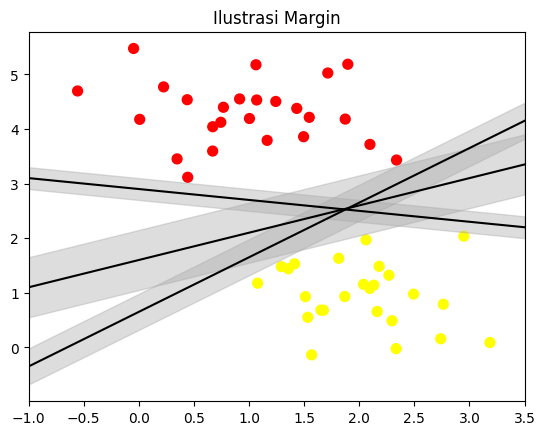

In [4]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d,
                     edgecolor='none', color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.title('Ilustrasi Margin')
plt.show()

## Langkah 5 — Fitting Model SVM Linier
Melatih model menggunakan kernel linier. Nilai `C` besar berusaha memisahkan data latihan dengan ketat.

In [5]:
model_linear = SVC(kernel='linear', C=1E10)
model_linear.fit(X, y)
print('Jumlah support vector:', len(model_linear.support_vectors_))
print('Support vectors:\n', model_linear.support_vectors_)

Jumlah support vector: 3
Support vectors:
 [[0.44359863 3.11530945]
 [2.33812285 3.43116792]
 [2.06156753 1.96918596]]


### Langkah 5a — Fungsi Visualisasi Decision Boundary
Fungsi ini menggambar batas pemisah, margin, dan support vector.

In [6]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    x = np.linspace(xlim[0], xlim[1], 30)
    y_grid = np.linspace(ylim[0], ylim[1], 30)
    Y_grid, X_grid = np.meshgrid(y_grid, x)
    xy = np.vstack([X_grid.ravel(), Y_grid.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    ax.contour(X_grid, Y_grid, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none',
                   edgecolors='black')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### Langkah 5b — Visualisasi Hasil Model

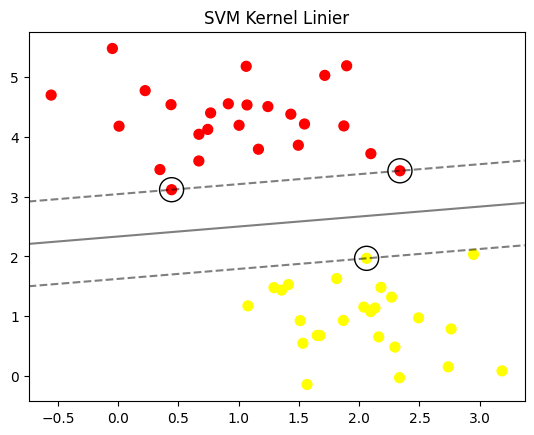

In [7]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model_linear)
plt.title('SVM Kernel Linier')
plt.show()

### Langkah 5c — Perbandingan Jumlah Data
Membandingkan hasil model dengan 60 dan 120 titik data.

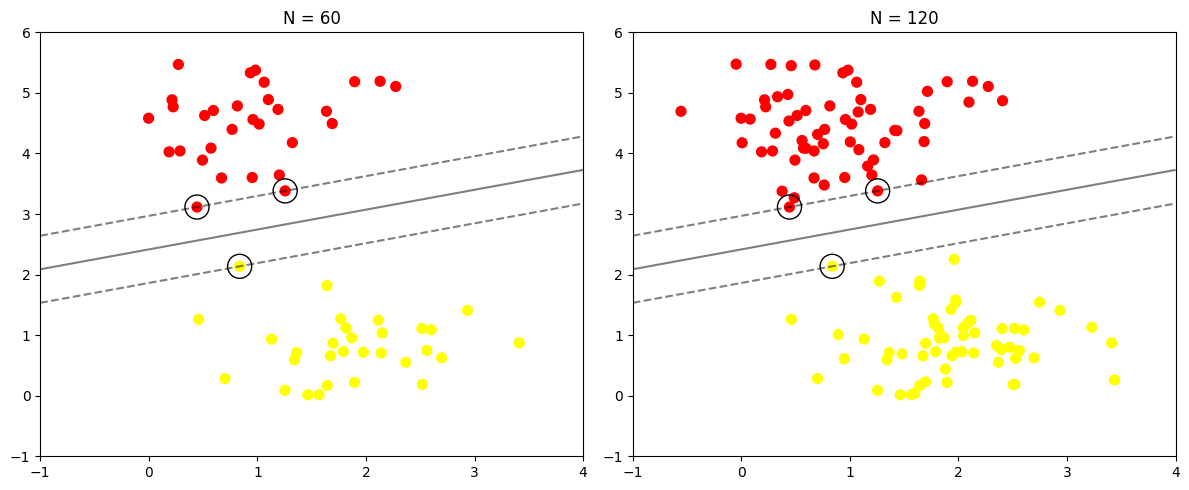

In [8]:
def plot_svm(N=60, ax=None):
    X_demo, y_demo = make_blobs(n_samples=200, centers=2,
                                random_state=0, cluster_std=0.60)
    X_demo, y_demo = X_demo[:N], y_demo[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X_demo, y_demo)

    if ax is None:
        ax = plt.gca()
    ax.scatter(X_demo[:, 0], X_demo[:, 1], c=y_demo, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)
    ax.set_title(f'N = {N}')

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
plot_svm(60, ax[0])
plot_svm(120, ax[1])
plt.tight_layout()
plt.show()

# Praktikum 2 — SVM dengan Data Dummy Non-Linier

## Langkah 1 — Membuat Data Non-Linier
Data berbentuk lingkaran tidak cocok dipisahkan menggunakan satu garis lurus.

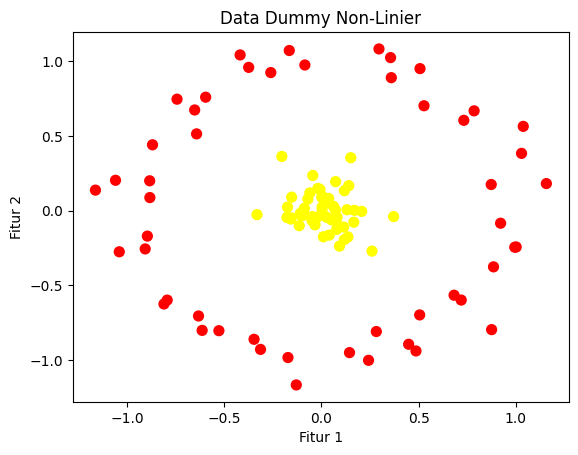

In [9]:
from sklearn.datasets import make_circles

X_circle, y_circle = make_circles(n_samples=100, factor=0.1,
                                  noise=0.1, random_state=42)
plt.scatter(X_circle[:, 0], X_circle[:, 1],
            c=y_circle, s=50, cmap='autumn')
plt.title('Data Dummy Non-Linier')
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.show()

### Langkah 1a — Mencoba Kernel Linier
Model linier ditampilkan sebagai pembanding; batasnya tidak dapat mengikuti bentuk lingkaran.

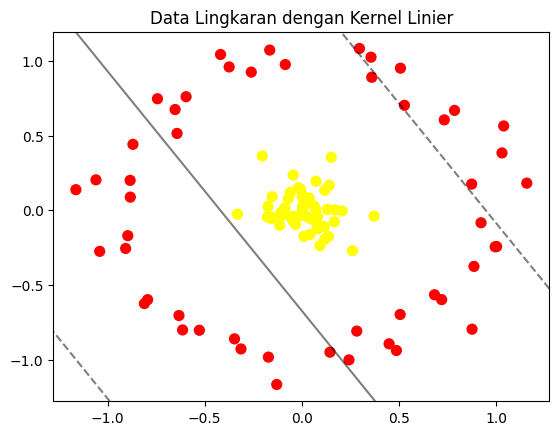

In [10]:
model_circle_linear = SVC(kernel='linear')
model_circle_linear.fit(X_circle, y_circle)

plt.scatter(X_circle[:, 0], X_circle[:, 1],
            c=y_circle, s=50, cmap='autumn')
plot_svc_decision_function(model_circle_linear, plot_support=False)
plt.title('Data Lingkaran dengan Kernel Linier')
plt.show()

### Langkah 1b — Ilustrasi Proyeksi 3D
Nilai radial membantu menggambarkan bahwa data lingkaran dapat dibedakan melalui dimensi tambahan.

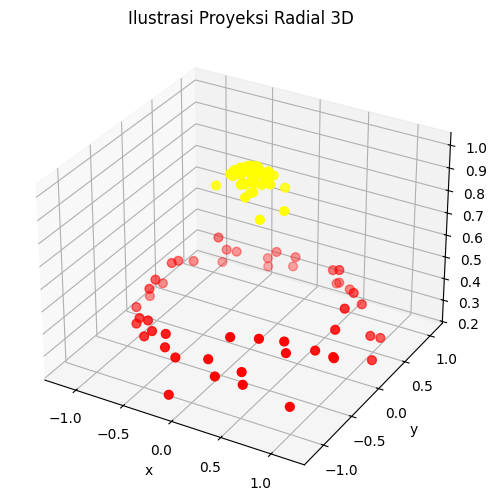

In [11]:
from mpl_toolkits.mplot3d import Axes3D

r = np.exp(-(X_circle ** 2).sum(axis=1))
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_circle[:, 0], X_circle[:, 1], r,
           c=y_circle, s=40, cmap='autumn')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('r')
ax.set_title('Ilustrasi Proyeksi Radial 3D')
plt.show()

## Langkah 2 — Fitting Model dengan Kernel RBF
Kernel RBF membantu membuat batas keputusan non-linier.

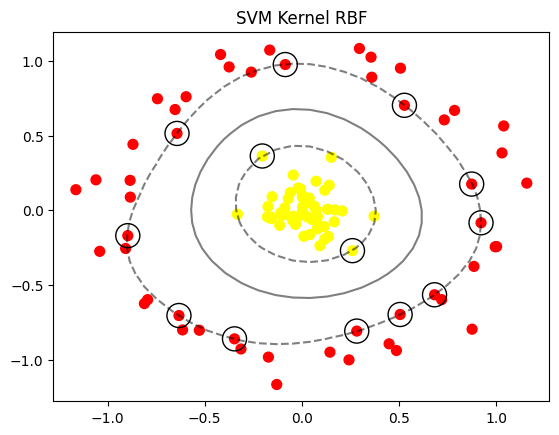

Akurasi pada data dummy: 1.0


In [12]:
model_rbf = SVC(kernel='rbf', C=1E3, gamma='scale')
model_rbf.fit(X_circle, y_circle)

plt.scatter(X_circle[:, 0], X_circle[:, 1],
            c=y_circle, s=50, cmap='autumn')
plot_svc_decision_function(model_rbf)
plt.title('SVM Kernel RBF')
plt.show()

print('Akurasi pada data dummy:', model_rbf.score(X_circle, y_circle))

# Praktikum 3 — SVM pada Data Overlapping

## Langkah 1 — Membuat Data Overlapping
Data dibuat lebih menyebar sehingga dua kelas dapat saling bertumpang tindih.

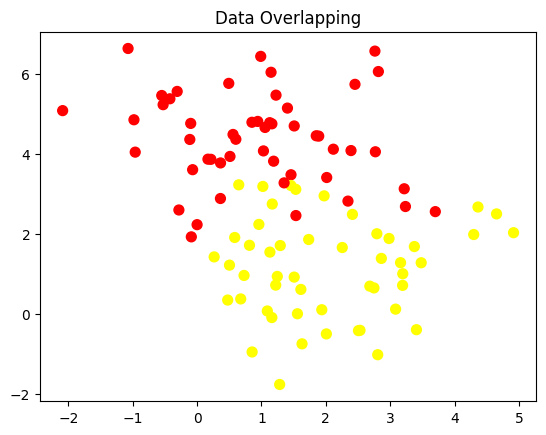

In [13]:
X_overlap, y_overlap = make_blobs(n_samples=100, centers=2,
                                   random_state=0, cluster_std=1.2)
plt.scatter(X_overlap[:, 0], X_overlap[:, 1],
            c=y_overlap, s=50, cmap='autumn')
plt.title('Data Overlapping')
plt.show()

## Langkah 2 — Membandingkan Parameter C
`C` mengatur seberapa besar model menghukum kesalahan klasifikasi. C besar cenderung lebih ketat, sedangkan C kecil memberi margin lebih longgar.

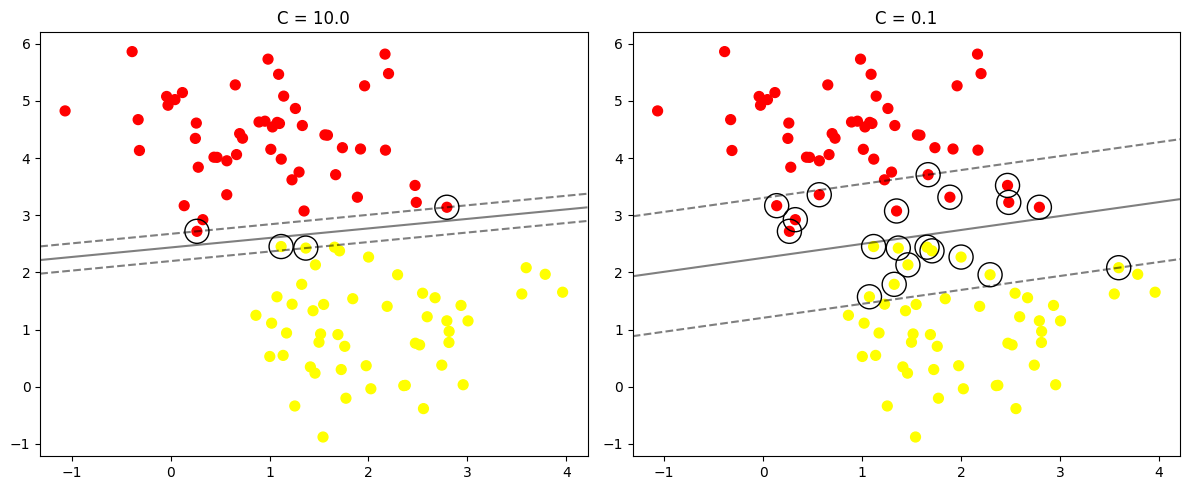

In [14]:
X_overlap, y_overlap = make_blobs(n_samples=100, centers=2,
                                   random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C)
    model.fit(X_overlap, y_overlap)
    axi.scatter(X_overlap[:, 0], X_overlap[:, 1],
                c=y_overlap, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.set_title(f'C = {C}')
plt.tight_layout()
plt.show()

# Praktikum 4 — Klasifikasi Citra Wajah

Dataset wajah akan diunduh oleh scikit-learn. Proses ini membutuhkan internet dan waktu komputasi, terutama saat pertama kali dijalankan.

## Langkah 1 — Unduh dan Inspeksi Dataset

In [15]:
from sklearn.datasets import fetch_lfw_people

faces = fetch_lfw_people(min_faces_per_person=60)
print('Nama kelas:', faces.target_names)
print('Jumlah kelas:', len(faces.target_names))
print('Bentuk citra:', faces.images.shape)
print('Bentuk fitur:', faces.data.shape)

Nama kelas: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
Jumlah kelas: 8
Bentuk citra: (1348, 62, 47)
Bentuk fitur: (1348, 2914)


### Langkah 1a — Menampilkan Contoh Citra

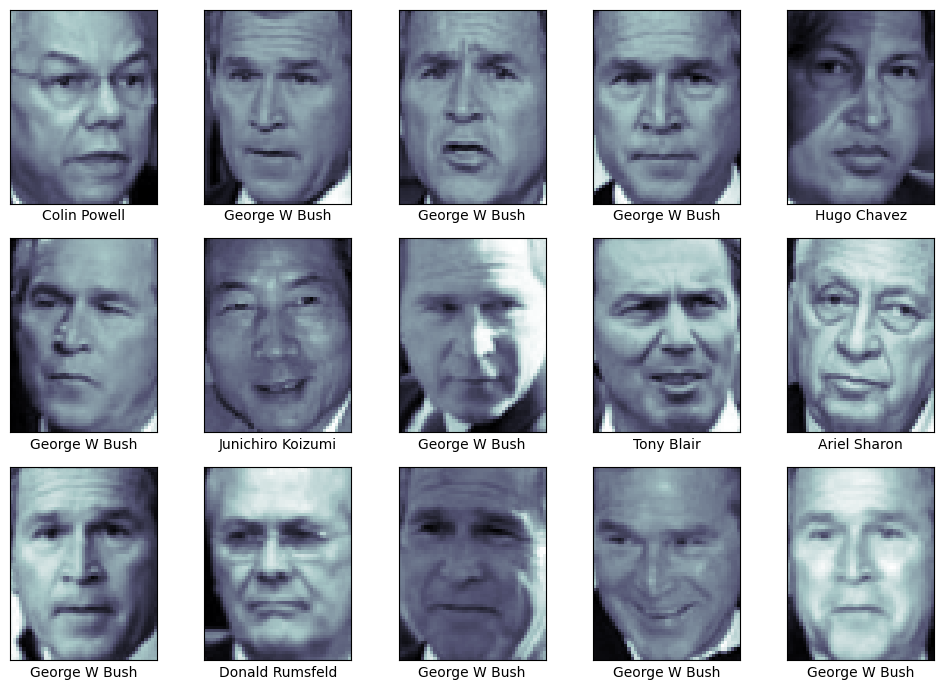

In [16]:
fig, ax = plt.subplots(3, 5, figsize=(10, 7))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.tight_layout()
plt.show()

## Langkah 2 — Membuat Pipeline PCA dan SVM
PCA mengurangi jumlah fitur citra. Pipeline menggabungkan PCA dan SVM dalam satu alur.

In [17]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV

n_components = min(150, faces.data.shape[0] - 1, faces.data.shape[1])
pca = PCA(n_components=n_components, whiten=True, random_state=42, svd_solver='randomized')
svc = SVC(kernel='rbf', class_weight='balanced')
face_model = make_pipeline(pca, svc)

## Langkah 3 — Split Data
Memisahkan data untuk pelatihan dan pengujian.

In [18]:
Xtrain, Xtest, ytrain, ytest = train_test_split(
    faces.data, faces.target, random_state=42, stratify=faces.target
)
print('Data latih:', Xtrain.shape[0])
print('Data uji:', Xtest.shape[0])

Data latih: 1011
Data uji: 337


## Langkah 4 — Tuning Hyperparameter
GridSearchCV mencoba beberapa kombinasi C dan gamma untuk mencari kombinasi yang memberikan skor validasi terbaik. Proses ini bisa memerlukan waktu.

In [19]:
param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]
}
grid = GridSearchCV(face_model, param_grid, cv=3, n_jobs=-1)
grid.fit(Xtrain, ytrain)

print('Parameter terbaik:', grid.best_params_)
print('Skor validasi terbaik:', round(grid.best_score_, 4))

Parameter terbaik: {'svc__C': 5, 'svc__gamma': 0.001}
Skor validasi terbaik: 0.817


## Langkah 5 — Prediksi dan Evaluasi
Menampilkan laporan klasifikasi dan confusion matrix pada data uji.

Akurasi data uji: 0.857566765578635
                   precision    recall  f1-score   support

     Ariel Sharon       0.72      0.68      0.70        19
     Colin Powell       0.81      0.92      0.86        59
  Donald Rumsfeld       0.83      0.83      0.83        30
    George W Bush       0.92      0.90      0.91       133
Gerhard Schroeder       0.76      0.93      0.83        27
      Hugo Chavez       0.91      0.56      0.69        18
Junichiro Koizumi       0.85      0.73      0.79        15
       Tony Blair       0.89      0.86      0.87        36

         accuracy                           0.86       337
        macro avg       0.84      0.80      0.81       337
     weighted avg       0.86      0.86      0.86       337



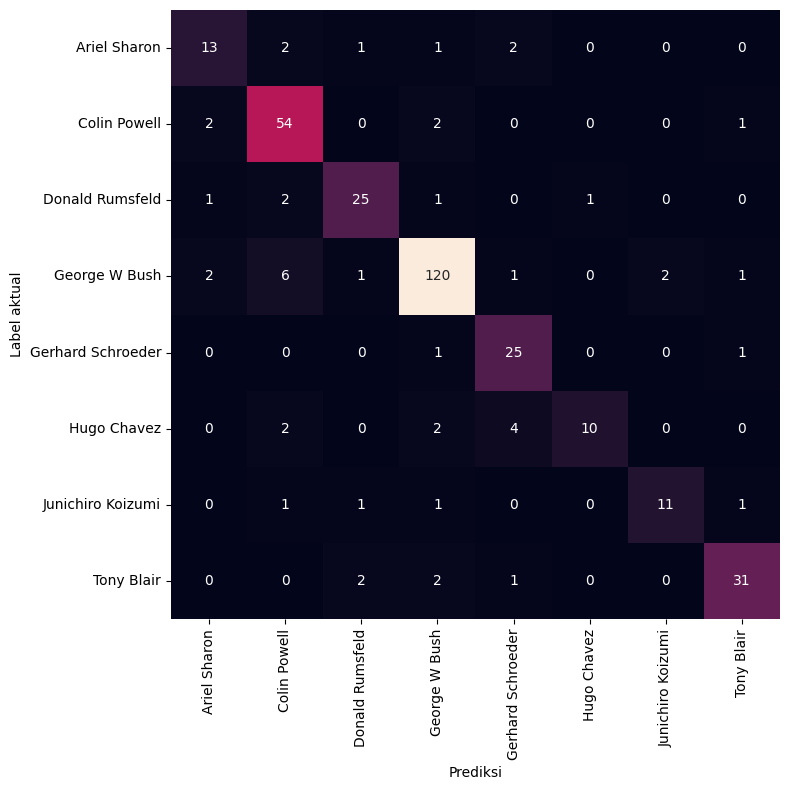

In [20]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

best_face_model = grid.best_estimator_
yfit = best_face_model.predict(Xtest)

print('Akurasi data uji:', accuracy_score(ytest, yfit))
print(classification_report(ytest, yfit, target_names=faces.target_names, zero_division=0))

mat = confusion_matrix(ytest, yfit)
plt.figure(figsize=(10, 8))
sns.heatmap(mat, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('Prediksi')
plt.ylabel('Label aktual')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Praktikum 5 — Klasifikasi Citra Siang dan Malam

## Langkah 0 — Import Library dan Menentukan Folder
Mengimpor pustaka untuk membaca, mengolah, dan menampilkan gambar.

In [21]:
from pathlib import Path
import zipfile
import cv2
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from google.colab import files

# Upload ZIP dataset jika folder gambar belum tersedia
if not Path('images/training').exists() or not Path('images/test').exists():
    print('Upload ZIP dataset Praktikum 5')
    uploaded = files.upload()
    zip_files = [name for name in uploaded if name.lower().endswith('.zip')]
    if zip_files:
        with zipfile.ZipFile(zip_files[0], 'r') as z:
            z.extractall('.')

train_dir = 'images/training/'
test_dir = 'images/test/'
print('Folder training tersedia:', Path(train_dir).exists())
print('Folder testing tersedia:', Path(test_dir).exists())

Upload ZIP dataset Praktikum 5


Saving images.zip to images.zip
Folder training tersedia: True
Folder testing tersedia: True


## Langkah 1 — Load Data dan Visualisasi
Membuat daftar gambar beserta label yang diambil dari nama foldernya, lalu menampilkan contoh gambar.

Jumlah gambar training: 240
Jumlah gambar testing: 160
Gambar: 234 | Label: night | Ukuran: (737, 1024, 3)


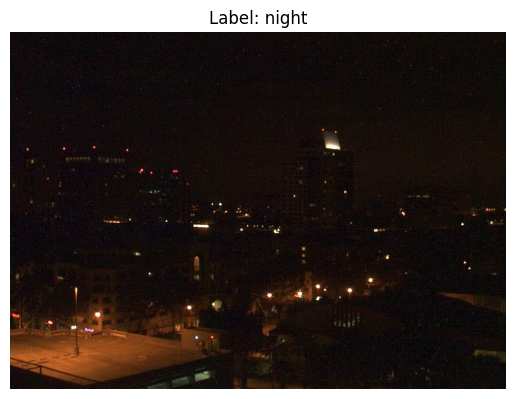

In [22]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    if not p.exists():
        return img_list
    for class_dir in p.iterdir():
        if class_dir.is_dir():
            label = class_dir.name.lower()
            for file in class_dir.glob('*'):
                if file.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                    img = mpimg.imread(file)
                    if img is not None:
                        img_list.append((img, label))
    return img_list

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)
print('Jumlah gambar training:', len(train_img))
print('Jumlah gambar testing:', len(test_img))

if train_img:
    idx = np.random.randint(len(train_img))
    img, label = train_img[idx]
    print('Gambar:', idx, '| Label:', label, '| Ukuran:', img.shape)
    plt.imshow(img)
    plt.title(f'Label: {label}')
    plt.axis('off')
    plt.show()
else:
    print('Gambar tidak ditemukan. Periksa struktur folder dataset.')

## Langkah 2 — Inspeksi Ukuran Gambar
Memeriksa ukuran gambar secara acak untuk melihat apakah dimensi gambar berbeda-beda.

In [23]:
if train_img:
    pick_random = np.random.randint(0, len(train_img))
    print(f'Gambar {pick_random}')
    print('Ukuran gambar:', train_img[pick_random][0].shape)

Gambar 62
Ukuran gambar: (555, 800, 3)


## Langkah 3 — Preprocessing dan Encoding Label
Semua gambar diubah ke ukuran 1100 × 600 piksel. Label `day` menjadi 1 dan `night` menjadi 0.

Jumlah data training: 240
Jumlah data testing: 160
Ukuran setelah preprocessing: (600, 1100, 3) | Label: 1


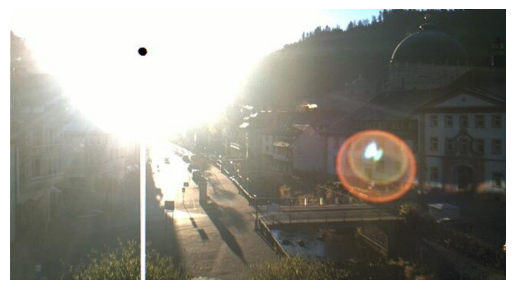

In [24]:
def standardized_input(image):
    return cv2.resize(image, (1100, 600))

def label_encoder(label):
    if label == 'day':
        return 1
    if label == 'night':
        return 0
    raise ValueError(f'Label tidak dikenali: {label}')

def preprocess(img_list):
    processed = []
    for image, label in img_list:
        processed.append((standardized_input(image), label_encoder(label)))
    return processed

train_std_img_list = preprocess(train_img)
test_std_img_list = preprocess(test_img)
print('Jumlah data training:', len(train_std_img_list))
print('Jumlah data testing:', len(test_std_img_list))
if train_std_img_list:
    pick_random = np.random.randint(len(train_std_img_list))
    img, label = train_std_img_list[pick_random]
    print('Ukuran setelah preprocessing:', img.shape, '| Label:', label)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

## Langkah 4 — Ekstraksi Fitur Rata-rata Kecerahan
Gambar diubah dari RGB ke HSV. Kanal `V` digunakan untuk menghitung rata-rata kecerahan gambar.

Gambar: 129
Rata-rata kecerahan: 95.4667
Label: 0


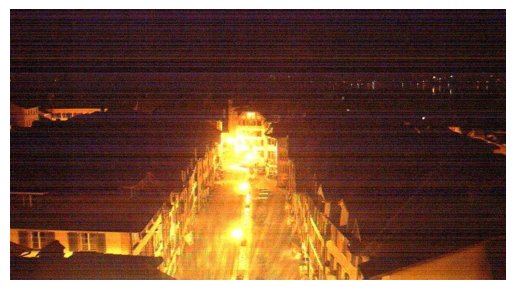

In [25]:
def avg_brightness(image):
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    return float(np.mean(img_hsv[:, :, 2]))

if train_std_img_list:
    rand_img = np.random.randint(len(train_std_img_list))
    feature_img, feature_label = train_std_img_list[rand_img]
    print('Gambar:', rand_img)
    print(f'Rata-rata kecerahan: {avg_brightness(feature_img):.4f}')
    print('Label:', feature_label)
    plt.imshow(feature_img)
    plt.axis('off')
    plt.show()

## Langkah 5 — Klasifikasi dengan Threshold
Jika rata-rata kecerahan lebih besar dari threshold, gambar diprediksi sebagai siang (1). Jika tidak, diprediksi malam (0).

Label aktual: 1
Label prediksi: 1


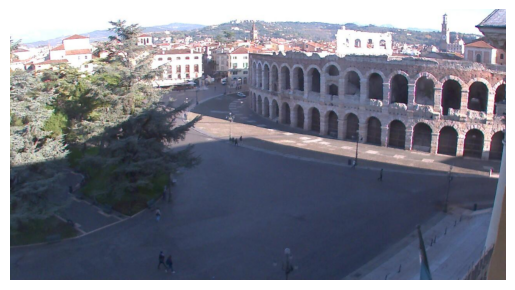

In [26]:
def predict_label(img, threshold=120):
    return 1 if avg_brightness(img) > threshold else 0

if train_std_img_list:
    rand_img = np.random.randint(len(train_std_img_list))
    img, actual = train_std_img_list[rand_img]
    pred = predict_label(img, threshold=120)
    print('Label aktual:', actual)
    print('Label prediksi:', pred)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

## Langkah 6 — Evaluasi Manual Threshold
Menghitung persentase prediksi yang benar. Nilai threshold dapat diubah untuk membandingkan hasil.

In [27]:
def evaluate_threshold(img_list, threshold=120):
    if not img_list:
        print('Data kosong. Periksa dataset.')
        return None
    actual = np.array([label for img, label in img_list])
    pred = np.array([predict_label(img, threshold) for img, label in img_list])
    accuracy = np.mean(actual == pred)
    print(f'Threshold: {threshold} | Akurasi: {accuracy:.4f}')
    return accuracy

print('Evaluasi data training:')
train_threshold_acc = evaluate_threshold(train_std_img_list, threshold=120)
print('Evaluasi data testing:')
test_threshold_acc = evaluate_threshold(test_std_img_list, threshold=120)

Evaluasi data training:
Threshold: 120 | Akurasi: 0.8417
Evaluasi data testing:
Threshold: 120 | Akurasi: 0.8688


## Langkah 7 — Membuat Feature Vectors untuk SVM
Mengubah setiap gambar menjadi satu nilai fitur kecerahan dan satu label, kemudian menyimpannya dalam DataFrame.

In [28]:
def extract_avg_bright_feature(img_list):
    rows = []
    for img, label in img_list:
        rows.append({'AVG_BRIGHT': avg_brightness(img), 'LABELS': label})
    return pd.DataFrame(rows)

train_avg_img = extract_avg_bright_feature(train_std_img_list)
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print('Ukuran fitur training:', train_avg_img.shape)
display(train_avg_img.head())
print('Ukuran fitur testing:', test_avg_img.shape)
display(test_avg_img.head())

Ukuran fitur training: (240, 2)


,AVG_BRIGHT,LABELS
0,110.299155,1
1,105.506424,1
2,131.771191,1
3,116.668502,1
4,109.947203,1


Ukuran fitur testing: (160, 2)


,AVG_BRIGHT,LABELS
0,150.341579,1
1,116.048989,1
2,153.885708,1
3,140.594911,1
4,99.537641,1


## Langkah 8 — Membuat Model SVM
Melatih SVM dengan kernel RBF menggunakan fitur rata-rata kecerahan.

In [29]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

if not train_avg_img.empty and not test_avg_img.empty:
    X_train_bright = train_avg_img[['AVG_BRIGHT']].values
    y_train_bright = train_avg_img['LABELS'].values.astype(int)
    X_test_bright = test_avg_img[['AVG_BRIGHT']].values
    y_test_bright = test_avg_img['LABELS'].values.astype(int)

    model_brightness_svm = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
    model_brightness_svm.fit(X_train_bright, y_train_bright)
    print('Model SVM RBF berhasil dilatih.')
else:
    print('Data training/testing kosong. Pastikan dataset berhasil dibaca.')

Model SVM RBF berhasil dilatih.


## Langkah 9 — Evaluasi Model SVM
Membandingkan akurasi model pada data training dan data testing.

Akurasi training: 0.8583
Akurasi testing: 0.9000
              precision    recall  f1-score   support

       night       0.88      0.93      0.90        80
         day       0.92      0.88      0.90        80

    accuracy                           0.90       160
   macro avg       0.90      0.90      0.90       160
weighted avg       0.90      0.90      0.90       160



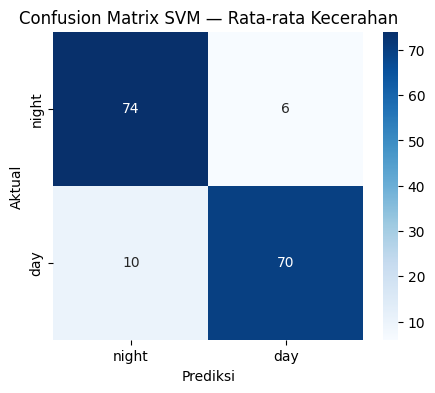

In [30]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

if not train_avg_img.empty and not test_avg_img.empty:
    pred_train_bright = model_brightness_svm.predict(X_train_bright)
    pred_test_bright = model_brightness_svm.predict(X_test_bright)
    print(f'Akurasi training: {accuracy_score(y_train_bright, pred_train_bright):.4f}')
    print(f'Akurasi testing: {accuracy_score(y_test_bright, pred_test_bright):.4f}')
    print(classification_report(y_test_bright, pred_test_bright,
                                labels=[0, 1], target_names=['night', 'day'], zero_division=0))
    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y_test_bright, pred_test_bright, labels=[0, 1]),
                annot=True, fmt='d', cmap='Blues',
                xticklabels=['night', 'day'], yticklabels=['night', 'day'])
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.title('Confusion Matrix SVM — Rata-rata Kecerahan')
    plt.show()

# Tugas 1 — Klasifikasi `voice.csv` dengan SVM

Dataset `voice.csv` harus tersedia di Colab. Sel berikut akan meminta upload file jika belum ditemukan. Jalankan seluruh langkah tugas secara berurutan.

## Langkah 1 — Load Dataset dan Eksplorasi

In [31]:
from pathlib import Path
import pandas as pd
from google.colab import files

if not Path('voice.csv').exists():
    print('Silakan upload file voice.csv')
    uploaded = files.upload()
    for name in uploaded:
        if name.lower().endswith('.csv'):
            Path(name).replace('voice.csv')
            break

voice = pd.read_csv('voice.csv')
display(voice.head())
print('Ukuran data:', voice.shape)
print('Kolom:', voice.columns.tolist())
print('\nJumlah label:')
print(voice['label'].value_counts())
print('\nData kosong:', voice.isnull().sum().sum())

Silakan upload file voice.csv


Saving voice.csv to voice.csv


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Ukuran data: (3168, 21)
Kolom: ['meanfreq', 'sd', 'median', 'Q25', 'Q75', 'IQR', 'skew', 'kurt', 'sp.ent', 'sfm', 'mode', 'centroid', 'meanfun', 'minfun', 'maxfun', 'meandom', 'mindom', 'maxdom', 'dfrange', 'modindx', 'label']

Jumlah label:
label
male      1584
female    1584
Name: count, dtype: int64

Data kosong: 0


## Langkah 2 — Menyiapkan Fitur dan Label
Semua kolom kecuali `label` digunakan sebagai fitur. StandardScaler penting karena skala fitur suara berbeda-beda.

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

voice = voice.dropna().copy()
X = voice.drop(columns=['label'])
y = voice['label'].astype(str).str.lower().str.strip()

print('Kelas:', y.value_counts())

Kelas: label
male      1584
female    1584
Name: count, dtype: int64


## Langkah 3 — Membandingkan 3 Kernel dan 2 Rasio Split
Menguji kernel linear, polynomial, dan RBF pada rasio 70:30 dan 80:20. Setiap model menggunakan standardisasi yang dipelajari dari data latih saja.

In [33]:
results = []
models = {}

for test_size in [0.30, 0.20]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    for kernel in ['linear', 'poly', 'rbf']:
        model = make_pipeline(
            StandardScaler(),
            SVC(kernel=kernel, degree=3, C=1.0, gamma='scale')
        )
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)

        split_label = f'{int((1-test_size)*100)}:{int(test_size*100)}'
        results.append({
            'Rasio Train:Test': split_label,
            'Kernel': kernel,
            'Akurasi': acc
        })
        models[(split_label, kernel)] = model
        print(f'Split {split_label} | Kernel {kernel} | Akurasi: {acc:.4f}')

results_df = pd.DataFrame(results)
display(results_df.pivot(index='Kernel', columns='Rasio Train:Test', values='Akurasi').round(4))

Split 70:30 | Kernel linear | Akurasi: 0.9790
Split 70:30 | Kernel poly | Akurasi: 0.9600
Split 70:30 | Kernel rbf | Akurasi: 0.9832
Split 80:20 | Kernel linear | Akurasi: 0.9748
Split 80:20 | Kernel poly | Akurasi: 0.9558
Split 80:20 | Kernel rbf | Akurasi: 0.9826


Rasio Train:Test,70:30,80:20
Kernel,,
linear,0.9790,0.9748
poly,0.9600,0.9558
rbf,0.9832,0.9826


## Langkah 4 — Grafik Perbandingan Akurasi
Grafik membantu melihat kernel mana yang memberikan akurasi terbaik pada masing-masing rasio split.

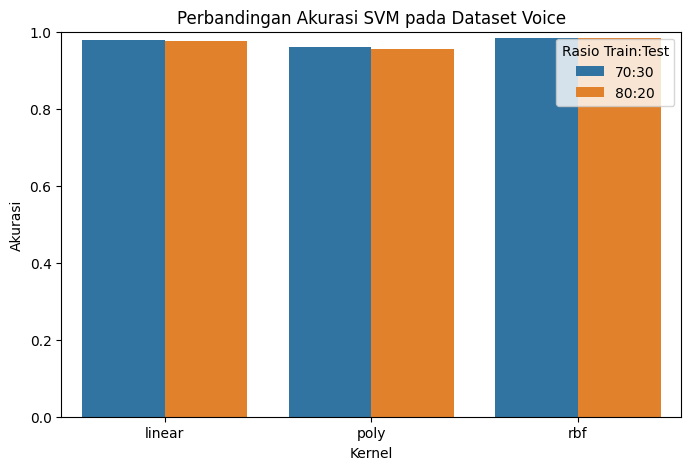

Kombinasi terbaik:
Rasio Train:Test       70:30
Kernel                   rbf
Akurasi             0.983176


In [34]:
plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x='Kernel', y='Akurasi', hue='Rasio Train:Test')
plt.ylim(0, 1)
plt.title('Perbandingan Akurasi SVM pada Dataset Voice')
plt.ylabel('Akurasi')
plt.show()

best_row = results_df.loc[results_df['Akurasi'].idxmax()]
print('Kombinasi terbaik:')
print(best_row.to_string())

## Langkah 5 — Evaluasi Model Terbaik
Menampilkan detail klasifikasi untuk kombinasi dengan akurasi tertinggi.

              precision    recall  f1-score   support

      female       0.99      0.98      0.98       476
        male       0.98      0.99      0.98       475

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



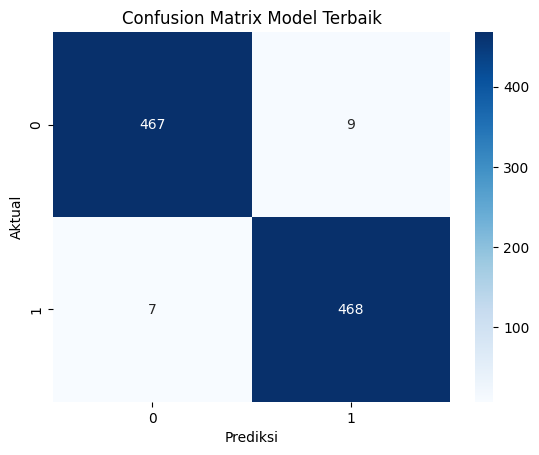

In [35]:
from sklearn.metrics import classification_report, confusion_matrix

best_split = best_row['Rasio Train:Test']
best_kernel = best_row['Kernel']
best_model = models[(best_split, best_kernel)]

test_size = 0.30 if best_split == '70:30' else 0.20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=42, stratify=y
)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred, zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_[1] if False else None)
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix Model Terbaik')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

# Tugas 2 — Klasifikasi Citra Siang dan Malam dengan SVM RBF

## Langkah 1 — Upload dan Ekstrak Dataset Citra

In [36]:
from pathlib import Path
import zipfile, os

from google.colab import files

if not Path('images/training').exists():
    print('Upload ZIP dataset Praktikum 5 (berisi folder images/training dan images/test)')
    uploaded = files.upload()
    zip_files = [name for name in uploaded if name.lower().endswith('.zip')]
    if zip_files:
        with zipfile.ZipFile(zip_files[0], 'r') as z:
            z.extractall('.')

print('Folder training ada:', Path('images/training').exists())
print('Folder testing ada:', Path('images/test').exists())
print('Folder kerja:', Path.cwd())

Folder training ada: True
Folder testing ada: True
Folder kerja: /content


## Langkah 2 — Load Data dan Lihat Contoh Gambar
Membaca gambar dari folder berdasarkan nama kelasnya.

Jumlah gambar latih: 240
Jumlah gambar uji: 160


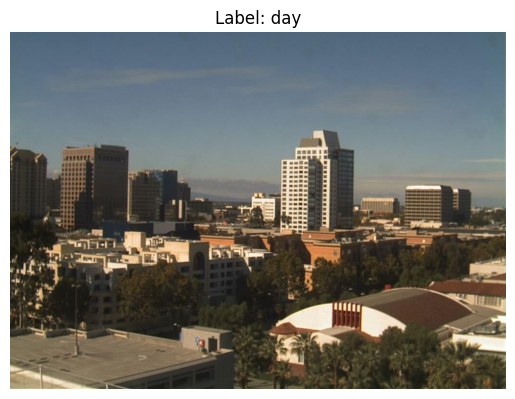

In [37]:
import cv2
import matplotlib.image as mpimg

def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    if not p.exists():
        return img_list
    for class_dir in p.iterdir():
        if class_dir.is_dir():
            label = class_dir.name.lower()
            for file in class_dir.glob('*'):
                if file.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                    img = mpimg.imread(file)
                    if img is not None:
                        img_list.append((img, label))
    return img_list

train_img = load_dataset('images/training')
test_img = load_dataset('images/test')

print('Jumlah gambar latih:', len(train_img))
print('Jumlah gambar uji:', len(test_img))
if train_img:
    plt.imshow(train_img[0][0])
    plt.title(f'Label: {train_img[0][1]}')
    plt.axis('off')
    plt.show()
else:
    print('Gambar tidak ditemukan. Periksa struktur folder ZIP.')

## Langkah 3 — Preprocessing dan Encoding Label
Ukuran gambar diseragamkan. Label `day` diubah menjadi 1 dan `night` menjadi 0.

In [38]:
def standardized_input(image, size=(1100, 600)):
    return cv2.resize(image, size)

def label_encoder(label):
    if label == 'day':
        return 1
    if label == 'night':
        return 0
    raise ValueError(f'Label tidak dikenali: {label}')

def preprocess(img_list):
    return [(standardized_input(img), label_encoder(label))
            for img, label in img_list]

train_std_img_list = preprocess(train_img)
test_std_img_list = preprocess(test_img)

print('Jumlah data latih setelah preprocessing:', len(train_std_img_list))
print('Jumlah data uji setelah preprocessing:', len(test_std_img_list))

Jumlah data latih setelah preprocessing: 240
Jumlah data uji setelah preprocessing: 160


## Langkah 4 — Ekstraksi Fitur Histogram HSV
Histogram warna digunakan sebagai fitur agar model dapat membedakan karakteristik warna siang dan malam. Setiap histogram dinormalisasi.

In [39]:
def extract_hsv_histogram(image, bins=(8, 8, 8)):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, bins,
                        [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist, hist)
    return hist.flatten()

X_train_img = np.array([extract_hsv_histogram(img) for img, label in train_std_img_list])
y_train_img = np.array([label for img, label in train_std_img_list])
X_test_img = np.array([extract_hsv_histogram(img) for img, label in test_std_img_list])
y_test_img = np.array([label for img, label in test_std_img_list])

print('Dimensi fitur training:', X_train_img.shape)
print('Dimensi fitur testing:', X_test_img.shape)

Dimensi fitur training: (240, 512)
Dimensi fitur testing: (160, 512)


## Langkah 5 — Training SVM dengan Kernel RBF
Rasio train:test mengikuti folder training dan testing dari dataset Praktikum 5. Model menggunakan kernel RBF dan standardisasi fitur histogram.

In [40]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

svm_rbf = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.001, 0.01, 0.1]
}
grid_img = GridSearchCV(svm_rbf, param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid_img.fit(X_train_img, y_train_img)

print('Parameter terbaik:', grid_img.best_params_)
print('Akurasi validasi terbaik:', round(grid_img.best_score_, 4))

Parameter terbaik: {'svc__C': 10, 'svc__gamma': 0.001}
Akurasi validasi terbaik: 0.9667


## Langkah 6 — Evaluasi pada Data Uji
Akurasi dihitung pada folder testing yang tidak digunakan untuk melatih model.

Akurasi data uji: 0.9250
              precision    recall  f1-score   support

       night       0.90      0.96      0.93        80
         day       0.96      0.89      0.92        80

    accuracy                           0.93       160
   macro avg       0.93      0.93      0.92       160
weighted avg       0.93      0.93      0.92       160



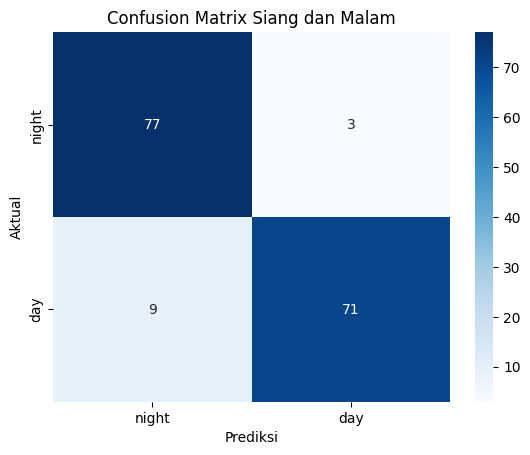

In [41]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_img = grid_img.best_estimator_.predict(X_test_img)
acc_img = accuracy_score(y_test_img, y_pred_img)
print(f'Akurasi data uji: {acc_img:.4f}')
print(classification_report(y_test_img, y_pred_img,
                            labels=[0, 1], target_names=['night', 'day'],
                            zero_division=0))

sns.heatmap(confusion_matrix(y_test_img, y_pred_img, labels=[0, 1]),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['night', 'day'], yticklabels=['night', 'day'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix Siang dan Malam')
plt.show()